# Pipeline Introduction


Follow _Introduction to Machine Learning_ [Chapter 6](https://github.com/amueller/introduction_to_ml_with_python/blob/master/06-algorithm-chains-and-pipelines.ipynb):
-  6. Algorithm Chains and Pipelines to 6.4 The General Pipeline interface 





In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
import mglearn

As an example of the importance of chaining models, we noticed that we can greatly improve the performance of a kernel SVM on the `cancer` dataset by using the `MinMaxScaler` for preprocessing. Here’s code for splitting the data, scaling the data, and training the SVM:

## Scaling -> classification  on breast cancer dataset (review)

In [17]:
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# load and split the data
cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0)

# fit scaler on the training data
scaler = MinMaxScaler().fit(X_train)

In [18]:
# rescale the training data
X_train_scaled = scaler.transform(X_train)

svm = SVC()
# learn an SVM on the scaled training data
svm.fit(X_train_scaled, y_train)
# scale the test data and score the scaled data
X_test_scaled = scaler.transform(X_test)
print("Test score: {:.2f}".format(svm.score(X_test_scaled, y_test)))

Test score: 0.97


## Using grid search to find better parameters - Naive approach

Now let’s say we want to find better parameters for SVC using GridSearchCV. How should we go about doing this? A naive approach might look like this:

In [19]:
from sklearn.model_selection import GridSearchCV
# for illustration purposes only, don't use this code!
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100],
              'gamma': [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(SVC(), param_grid=param_grid, cv=5)
grid.fit(X_train_scaled, y_train)
print("Best cross-validation accuracy: {:.2f}".format(grid.best_score_))
print("Best parameters: ", grid.best_params_)
print("Test set accuracy: {:.2f}".format(grid.score(X_test_scaled, y_test)))

Best cross-validation accuracy: 0.98
Best parameters:  {'C': 1, 'gamma': 1}
Test set accuracy: 0.97


- When scaling the data, we used all the data in the training set to compute the minimum and maximum of the data
- We then use the scaled training data to run our grid search using cross-validation

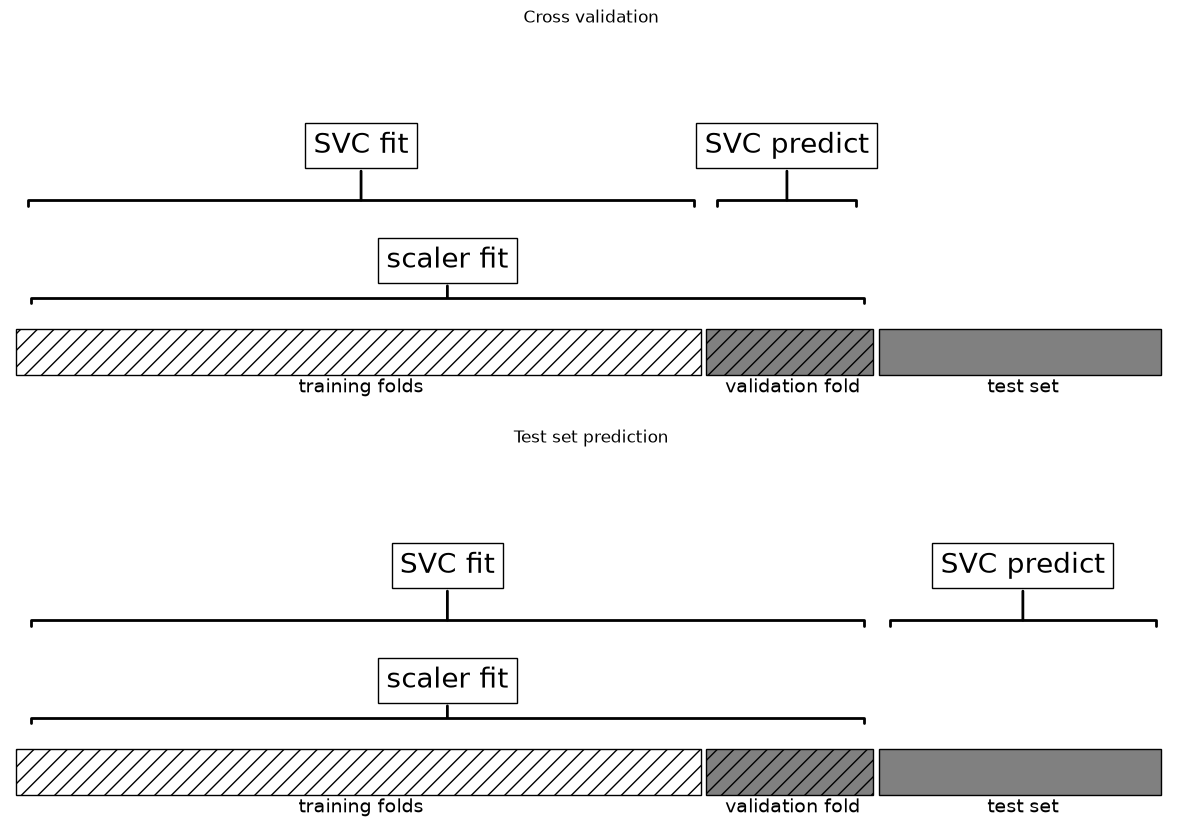

In [20]:
mglearn.plots.plot_improper_processing()

>So, the splits in the cross-validation no longer correctly mirror how new data will look to the modeling process. We already leaked information from these parts of the data into our modeling process. This will lead to overly optimistic results during cross-validation, and possibly the selection of suboptimal parameters.

## ILLUSTRATING INFORMATION LEAKAGE 
>Let’s consider a synthetic regression task with 100 samples and 10,000 features that are sampled independently from a Gaussian distribution. We also sample the response from a Gaussian distribution:

In [21]:
rnd = np.random.RandomState(seed=0)
X = rnd.normal(size=(100, 10000))
y = rnd.normal(size=(100,))

>Given the way we created the dataset, there is no relation between the data, X, and the target, y (they are independent), so it should not be possible to learn anything from this dataset.

>First, select the most informative of the 10,000 features using SelectPercentile feature selection, and then we evaluate a Ridge regressor using cross-validation:

In [8]:
from sklearn.feature_selection import SelectPercentile, f_regression

select = SelectPercentile(score_func=f_regression, percentile=5).fit(X, y)
X_selected = select.transform(X)
print("X_selected.shape: {}".format(X_selected.shape))

X_selected.shape: (100, 500)


In [22]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge
print("Cross-validation accuracy (cv only on ridge): {:.2f}".format(
      np.mean(cross_val_score(Ridge(), X_selected, y, cv=5))))

Cross-validation accuracy (cv only on ridge): 0.91


> The mean R2 computed by cross-validation is 0.91, indicating a very good model. This clearly cannot be right, as our data is entirely random. 

>Let’s compare this to a proper cross-validation using a pipeline:

In [10]:
from sklearn.pipeline import Pipeline
pipe = Pipeline([("select", SelectPercentile(score_func=f_regression,
                                             percentile=5)),
                 ("ridge", Ridge())])
print("Cross-validation accuracy (pipeline): {:.2f}".format(
      np.mean(cross_val_score(pipe, X, y, cv=5))))

Cross-validation accuracy (pipeline): -0.25


>This time, we get a negative R2 score, indicating a very poor model. Using the pipeline, the feature selection is now inside the cross-validation loop. This means features can only be selected using the training folds of the data, not the test fold.

>The feature selection finds features that are correlated with the target on the training set, but because the data is entirely random, these features are not correlated with the target on the test set. In this example, rectifying the data leakage issue in the feature selection makes the difference between concluding that a model works very well and concluding that a model works not at all.

## Building pipelines

In [11]:
from sklearn.pipeline import Pipeline
pipe = Pipeline([("scaler", MinMaxScaler()), ("svm", SVC())])

In [12]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value


In [23]:
print("Test score: {:.2f}".format(pipe.score(X_test, y_test)))

Test score: 0.97


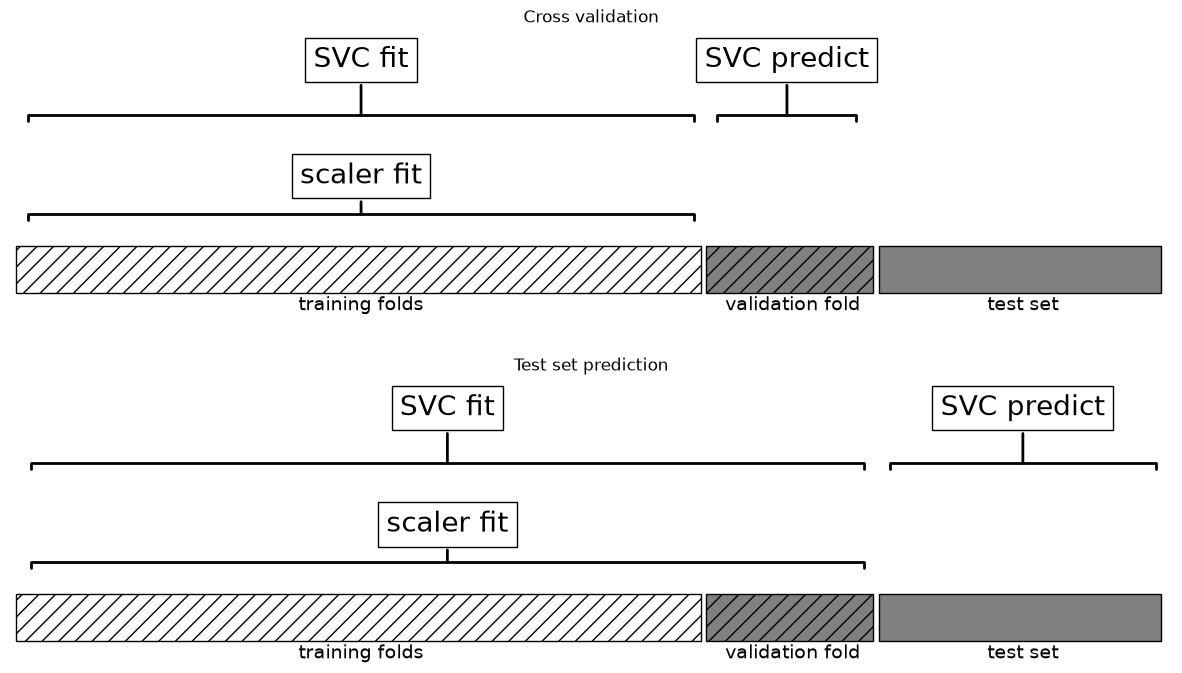

In [14]:
mglearn.plots.plot_proper_processing()

>Calling the score method on the pipeline first transforms the test data using the scaler, and then calls the score method on the SVM using the scaled test data. As you can see, the result is identical to the one we got from the code at the beginning of the chapter, when doing the transformations by hand. Using the pipeline, we reduced the code needed for our “preprocessing + classification” process. The main benefit of using the pipeline, however, is that we can now use this single estimator in cross_val_score or GridSearchCV.

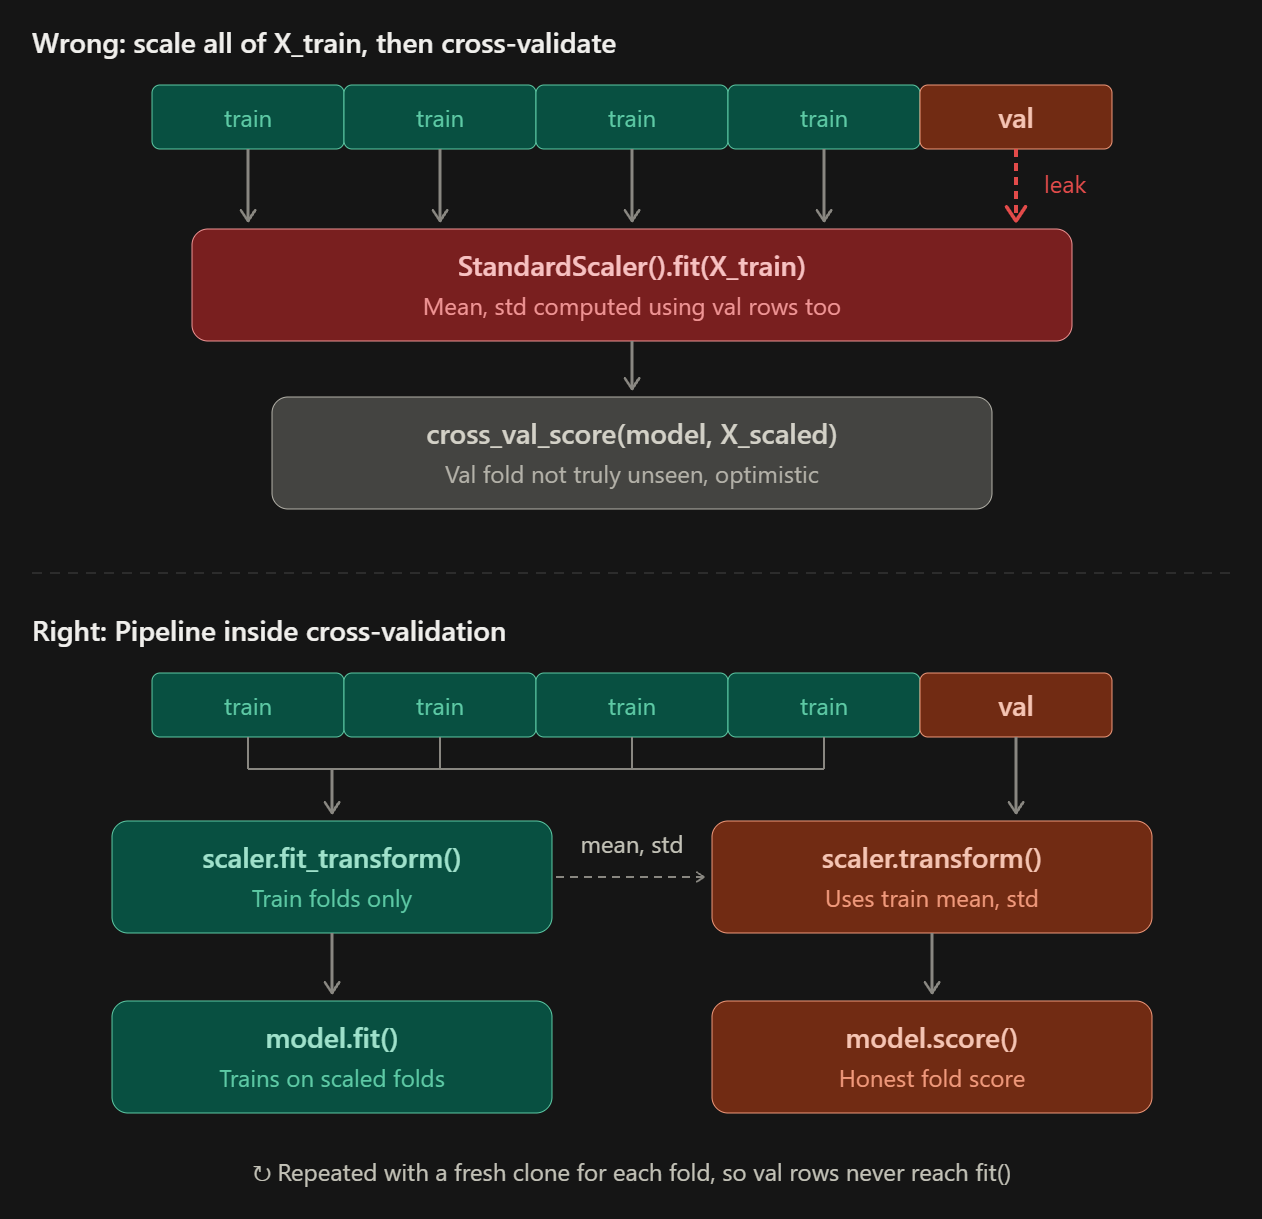
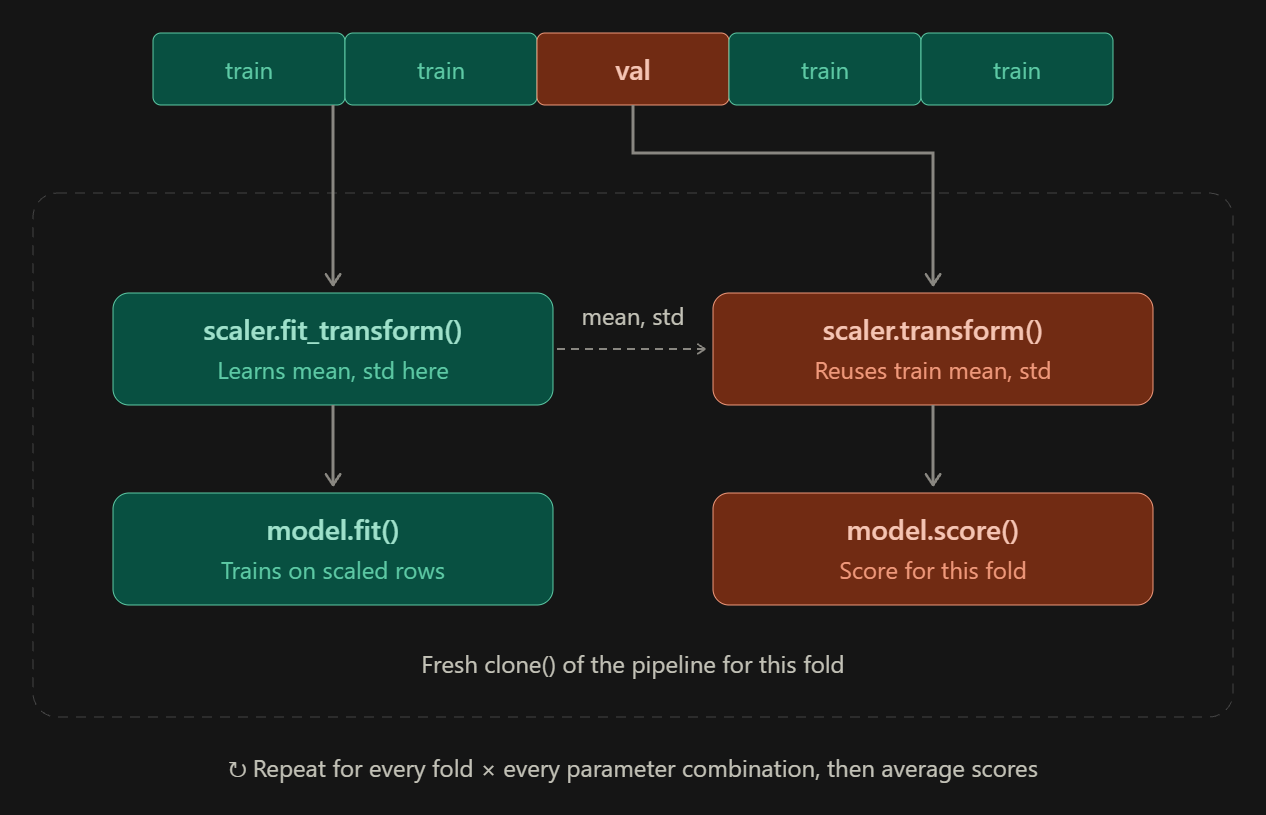

## Using pipelines in grid searches

We use the named step in the pipeline, followed by two underscores, then the hyper-parameter name to define the grid parameters:

In [24]:
param_grid = {'svm__C': [0.001, 0.01, 0.1, 1, 10, 100],
              'svm__gamma': [0.001, 0.01, 0.1, 1, 10, 100]}

In [25]:
grid = GridSearchCV(pipe, param_grid=param_grid, cv=5)
grid.fit(X_train, y_train)
print("Best cross-validation accuracy: {:.2f}".format(grid.best_score_))
print("Test set score: {:.2f}".format(grid.score(X_test, y_test)))
print("Best parameters: {}".format(grid.best_params_))

Best cross-validation accuracy: 0.98
Test set score: 0.97
Best parameters: {'svm__C': 1, 'svm__gamma': 1}


![](pipeline.png)